# 01 — Wind Farm SCADA Data Exploration

**Farms:** A · B · C &nbsp;|&nbsp; **Goal:** Understand the dataset structure before building a predictive maintenance model.

---

| # | Section | Purpose |
|---|---------|---------|
| 1 | Configuration & Helpers | Paths, constants, utility functions |
| 2 | Event Metadata | Class balance, fault types, event duration |
| 3 | Dataset Inventory | File counts, row counts, integrity check |
| 4 | Schema Inspection | Column overview, sensor types, cross-farm overlap |
| 5 | Descriptive Statistics | Mean, std, percentiles for sensor columns |
| 6 | Missing Value Analysis | Per-column missingness visualisation |
| 7 | Normal vs. Anomaly Comparison | Side-by-side sensor behaviour |
| 8 | Key Findings | Observations to guide preprocessing |


In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
PROJECT_ROOT = Path("..")
RAW_DIR = PROJECT_ROOT / "data" / "raw"

# Farm A uses "dataset" (singular), farms B and C use "datasets" (plural)
FARMS = {
    "A": {
        "base_dir": RAW_DIR / "windfarmA",
        "dataset_dir": RAW_DIR / "windfarmA" / "dataset",
        "event_info_path": RAW_DIR / "windfarmA" / "event_info.csv",
    },
    "B": {
        "base_dir": RAW_DIR / "windfarmB",
        "dataset_dir": RAW_DIR / "windfarmB" / "datasets",
        "event_info_path": RAW_DIR / "windfarmB" / "event_info.csv",
    },
    "C": {
        "base_dir": RAW_DIR / "windfarmC",
        "dataset_dir": RAW_DIR / "windfarmC" / "datasets",
        "event_info_path": RAW_DIR / "windfarmC" / "event_info.csv",
    },
}

for farm_name, paths in FARMS.items():
    print(f"Wind Farm {farm_name}:")
    print(f"  Dataset dir exists : {paths['dataset_dir'].exists()}")
    print(f"  event_info.csv exists: {paths['event_info_path'].exists()}")


Wind Farm A:
  Dataset dir exists : True
  event_info.csv exists: True
Wind Farm B:
  Dataset dir exists : True
  event_info.csv exists: True
Wind Farm C:
  Dataset dir exists : True
  event_info.csv exists: True


In [3]:
def read_csv_auto(path):
    """
    Read CSV file by trying common separators.
    """
    separators = [";", ","]
    
    best_df = None
    best_num_columns = 0
    
    for sep in separators:
        try:
            df = pd.read_csv(path, sep=sep)
            if df.shape[1] > best_num_columns:
                best_df = df
                best_num_columns = df.shape[1]
        except Exception:
            continue
    
    if best_df is None:
        raise ValueError(f"Could not read file: {path}")
    
    return best_df

In [4]:
event_info_all = {}

for farm_name, paths in FARMS.items():
    df = read_csv_auto(paths["event_info_path"])
    event_info_all[farm_name] = df
    print(f"=== Wind Farm {farm_name} ===")
    display(df.head())


=== Wind Farm A ===


,event_id,event_label,event_start,event_start_id,event_end,event_end_id,event_description
0,68,anomaly,2015-07-29 13:20:00,52063,2015-08-12 13:10:00,54076,Transformer failure
1,22,anomaly,2021-08-11 09:50:00,51888,2021-08-18 10:00:00,52892,Hydraulic group
2,72,anomaly,2021-10-09 08:40:00,52497,2021-10-16 08:40:00,53505,Gearbox failure
3,73,anomaly,2023-06-09 11:40:00,52745,2023-06-16 11:40:00,53753,Hydraulic group
4,0,anomaly,2022-08-05 06:10:00,52436,2022-08-19 06:10:00,54447,Generator bearing failure


=== Wind Farm B ===


,event_id,event_label,event_start,event_start_id,event_end,event_end_id,event_description
0,34,anomaly,2019-08-25 00:00:00,52531,2019-09-16 00:00:00,55699,high temperature
1,7,anomaly,2026-06-30 00:00:00,52703,2026-07-31 00:00:00,57167,high temperature
2,53,anomaly,2019-12-27 16:40:00,52559,2020-02-07 16:30:00,58606,Rotor Bearing 2 - Damage
3,27,anomaly,2018-09-02 00:00:00,52619,2018-11-02 00:00:00,61403,Turbine is stopped due to a main bearing damage
4,19,anomaly,2025-02-02 00:00:00,52673,2025-02-22 00:00:00,55553,high temperature


=== Wind Farm C ===


,event_id,event_label,event_start,event_start_id,event_end,event_end_id,event_description
0,55,anomaly,2018-10-29 11:30:00,52848,2018-11-15 15:30:00,55320,Harting plug Nacelle/HUB damaged + NCR20_HUB: ...
1,81,anomaly,2019-11-17 01:30:00,52704,2019-11-19 14:00:00,53067,Converter Failure from 17.11 12:30 - 18.11. 13...
2,47,anomaly,2018-12-23 15:00:00,52416,2018-12-28 13:40:00,53128,Failure due to Rotorbrake and Hydraulic proble...
3,12,anomaly,2025-06-25 00:00:00,52560,2025-07-17 15:00:00,55818,"10115 : Oil level error, two-pump mode + Oil L..."
4,4,anomaly,2026-07-29 10:00:00,52992,2026-08-17 10:00:00,55728,23020 : Axis 3 not ready-to-operate


In [5]:
for farm_name, event_info in event_info_all.items():
    print(f"=== Wind Farm {farm_name} ===")
    print("Shape:", event_info.shape)
    event_info.info()
    print()


=== Wind Farm A ===
Shape: (22, 7)
<class 'pandas.DataFrame'>
RangeIndex: 22 entries, 0 to 21
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   event_id           22 non-null     int64
 1   event_label        22 non-null     str  
 2   event_start        22 non-null     str  
 3   event_start_id     22 non-null     int64
 4   event_end          22 non-null     str  
 5   event_end_id       22 non-null     int64
 6   event_description  11 non-null     str  
dtypes: int64(3), str(4)
memory usage: 2.5 KB

=== Wind Farm B ===
Shape: (15, 7)
<class 'pandas.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype
---  ------             --------------  -----
 0   event_id           15 non-null     int64
 1   event_label        15 non-null     str  
 2   event_start        15 non-null     str  
 3   event_start_id     15 non-null     int64
 4   event_

In [6]:
for farm_name, event_info in event_info_all.items():
    print(f"=== Wind Farm {farm_name} ===")
    display(event_info["event_label"].value_counts())
    print()


=== Wind Farm A ===


event_label
anomaly    11
normal     11
Name: count, dtype: int64


=== Wind Farm B ===


event_label
normal     9
anomaly    6
Name: count, dtype: int64


=== Wind Farm C ===


event_label
normal     31
anomaly    27
Name: count, dtype: int64

C:\Users\mohamad\AppData\Local\Temp\ipykernel_9132\936533272.py:11: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


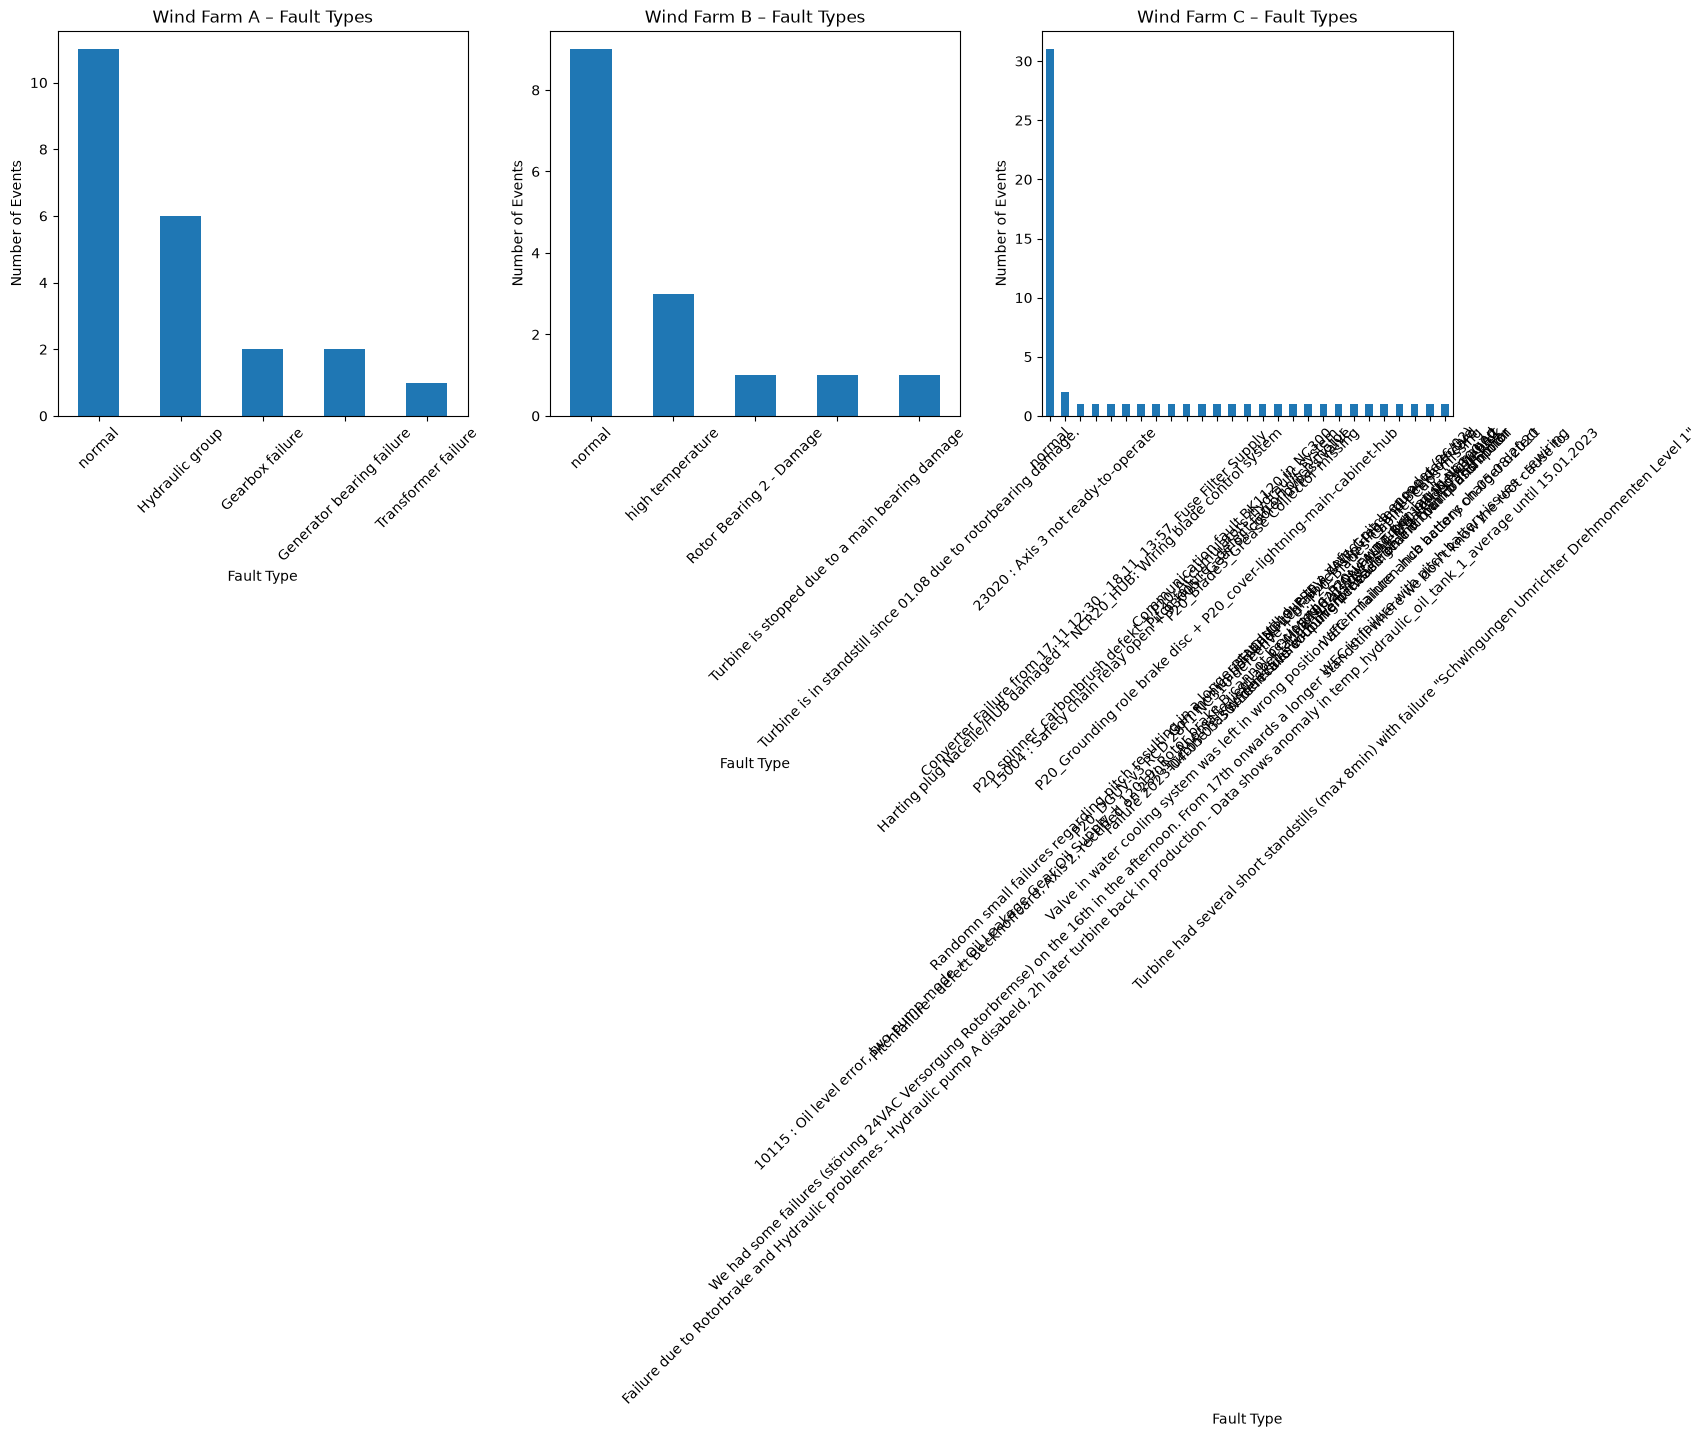

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (farm_name, event_info) in zip(axes, event_info_all.items()):
    counts = event_info["event_description"].fillna("normal").value_counts()
    counts.plot(kind="bar", ax=ax)
    ax.set_title(f"Wind Farm {farm_name} – Fault Types")
    ax.set_xlabel("Fault Type")
    ax.set_ylabel("Number of Events")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


In [8]:
csv_files_all = {}

for farm_name, paths in FARMS.items():
    csv_files = sorted(paths["dataset_dir"].glob("*.csv"))
    csv_files_all[farm_name] = csv_files
    print(f"=== Wind Farm {farm_name} === ({len(csv_files)} files)")
    for f in csv_files:
        print(" ", f.name)
    print()


=== Wind Farm A === (22 files)
  0.csv
  10.csv
  13.csv
  14.csv
  17.csv
  22.csv
  24.csv
  25.csv
  26.csv
  3.csv
  38.csv
  40.csv
  42.csv
  45.csv
  51.csv
  68.csv
  69.csv
  71.csv
  72.csv
  73.csv
  84.csv
  92.csv

=== Wind Farm B === (15 files)
  19.csv
  2.csv
  21.csv
  23.csv
  27.csv
  34.csv
  52.csv
  53.csv
  7.csv
  74.csv
  77.csv
  82.csv
  83.csv
  86.csv
  87.csv

=== Wind Farm C === (58 files)
  1.csv
  11.csv
  12.csv
  15.csv
  16.csv
  18.csv
  20.csv
  28.csv
  29.csv
  30.csv
  31.csv
  32.csv
  33.csv
  35.csv
  36.csv
  37.csv
  39.csv
  4.csv
  41.csv
  43.csv
  44.csv
  46.csv
  47.csv
  48.csv
  49.csv
  5.csv
  50.csv
  54.csv
  55.csv
  56.csv
  57.csv
  58.csv
  59.csv
  6.csv
  60.csv
  61.csv
  62.csv
  63.csv
  64.csv
  65.csv
  66.csv
  67.csv
  70.csv
  75.csv
  76.csv
  78.csv
  79.csv
  8.csv
  80.csv
  81.csv
  85.csv
  88.csv
  89.csv
  9.csv
  90.csv
  91.csv
  93.csv
  94.csv



In [9]:
for farm_name, event_info in event_info_all.items():
    csv_files = csv_files_all[farm_name]
    event_ids_from_info  = set(event_info["event_id"].astype(str))
    event_ids_from_files = set(f.stem for f in csv_files)

    missing_files = event_ids_from_info - event_ids_from_files
    extra_files   = event_ids_from_files - event_ids_from_info

    print(f"=== Wind Farm {farm_name} ===")
    print("  Missing files (in event_info but no CSV):", missing_files)
    print("  Extra files  (CSV but not in event_info):", extra_files)
    print()


=== Wind Farm A ===
  Missing files (in event_info but no CSV): set()
  Extra files  (CSV but not in event_info): set()

=== Wind Farm B ===
  Missing files (in event_info but no CSV): set()
  Extra files  (CSV but not in event_info): set()

=== Wind Farm C ===
  Missing files (in event_info but no CSV): set()
  Extra files  (CSV but not in event_info): set()



In [10]:
normal_samples = {}

for farm_name, event_info in event_info_all.items():
    paths = FARMS[farm_name]
    normal_rows = event_info.loc[event_info["event_label"] == "normal"]
    if normal_rows.empty:
        print(f"Wind Farm {farm_name}: no normal events found.")
        continue

    event_id = str(normal_rows["event_id"].iloc[0])
    file_path = paths["dataset_dir"] / f"{event_id}.csv"
    df = read_csv_auto(file_path)
    normal_samples[farm_name] = {"event_id": event_id, "df": df}

    print(f"=== Wind Farm {farm_name} – Normal Event {event_id} ===")
    print("Shape:", df.shape)
    display(df.head())
    print()


=== Wind Farm A – Normal Event 25 ===
Shape: (54712, 86)


,time_stamp,asset_id,id,train_test,status_type_id,sensor_0_avg,sensor_1_avg,sensor_2_avg,wind_speed_3_avg,wind_speed_4_avg,...,sensor_47,sensor_48,sensor_49,sensor_50,sensor_51,sensor_52_avg,sensor_52_max,sensor_52_min,sensor_52_std,sensor_53_avg
0,2022-05-22 06:50:00,11,0,train,5,18.0,161.3,156.2,2.4,2.4,...,-130.0,0.0,0.0,-682.0,-130.0,0.0,0.0,0.0,0.0,19.0
1,2022-05-22 07:00:00,11,1,train,5,18.0,172.3,167.1,2.8,2.8,...,-972.0,0.0,0.0,-996.0,-972.0,0.0,0.0,0.0,0.0,19.0
2,2022-05-22 07:10:00,11,2,train,5,18.0,173.0,41.0,3.1,3.1,...,-542.0,0.0,0.0,-849.0,-542.0,2.0,2.2,0.0,0.3,20.0
3,2022-05-22 07:20:00,11,3,train,5,18.0,168.4,5.6,2.4,2.4,...,-327.0,0.0,0.0,-781.0,-327.0,1.5,2.1,0.0,0.5,20.0
4,2022-05-22 07:30:00,11,4,train,5,18.0,155.4,-18.6,2.3,2.3,...,-253.0,0.0,0.0,-748.0,-253.0,1.2,1.9,0.0,0.8,20.0



=== Wind Farm B – Normal Event 83 ===
Shape: (66154, 257)


,time_stamp,asset_id,id,train_test,status_type_id,sensor_0_avg,sensor_0_max,sensor_0_min,sensor_0_std,sensor_1_avg,...,wind_speed_60_min,wind_speed_60_std,wind_speed_61_avg,wind_speed_61_max,wind_speed_61_min,wind_speed_61_std,power_62_avg,power_62_max,power_62_min,power_62_std
0,2025-06-28 00:00:00,2,0,train,0,0.0,0.0,0.0,0.0,0.0,...,0.00,1.34,12.73,16.22,1.15,9.27,1.028935,1.061942,0.013047,0.995432
1,2025-06-28 00:10:00,2,1,train,0,0.0,0.0,0.0,0.0,0.0,...,0.01,1.33,12.83,15.78,1.19,9.33,1.028029,1.057439,0.012095,0.980750
2,2025-06-28 00:20:00,2,2,train,0,0.0,0.0,0.0,0.0,0.0,...,0.01,1.35,12.49,15.53,1.22,7.81,1.027040,1.066502,0.016742,0.951750
3,2025-06-28 00:30:00,2,3,train,0,0.0,0.0,0.0,0.0,0.0,...,0.00,1.35,12.69,16.46,1.26,8.35,1.018698,1.071405,0.032102,0.838677
4,2025-06-28 00:40:00,2,4,train,0,0.0,0.0,0.0,0.0,0.0,...,0.01,1.35,12.70,16.29,1.21,9.09,1.016921,1.072250,0.033210,0.846253



=== Wind Farm C – Normal Event 8 ===
Shape: (54802, 957)


,time_stamp,asset_id,id,train_test,status_type_id,sensor_0_avg,sensor_0_max,sensor_0_min,sensor_0_std,sensor_1_avg,...,wind_speed_236_min,wind_speed_236_std,wind_speed_235_avg,wind_speed_235_max,wind_speed_235_min,wind_speed_235_std,wind_speed_237_avg,wind_speed_237_max,wind_speed_237_min,wind_speed_237_std
0,2023-08-22 17:00:00,50,0,train,0,0.0,0.0,0.0,0.0,0.0,...,0.00,0.2178,0.7263,1.5,0.0,0.3281,0.8377,1.5,0.0000,0.2287
1,2023-08-22 17:10:00,50,1,train,0,0.0,0.0,0.0,0.0,0.0,...,0.10,0.1634,0.6360,1.3,0.0,0.2609,0.7702,1.3,0.1000,0.1747
2,2023-08-22 17:20:00,50,2,train,0,0.0,0.0,0.0,0.0,0.0,...,0.85,0.1890,1.3180,1.7,0.8,0.2033,1.2330,1.6,0.8999,0.1774
3,2023-08-22 17:30:00,50,3,train,0,0.0,0.0,0.0,0.0,0.0,...,1.55,0.2309,2.1700,2.6,1.6,0.2461,2.0140,2.4,1.5000,0.2181
4,2023-08-22 17:40:00,50,4,train,0,0.0,0.0,0.0,0.0,0.0,...,2.40,0.0639,2.6600,2.8,2.5,0.0731,2.4550,2.6,2.3000,0.0592


In [11]:
anomaly_samples = {}

for farm_name, event_info in event_info_all.items():
    paths = FARMS[farm_name]
    anomaly_rows = event_info.loc[event_info["event_label"] == "anomaly"]
    if anomaly_rows.empty:
        print(f"Wind Farm {farm_name}: no anomaly events found.")
        continue

    event_id = str(anomaly_rows["event_id"].iloc[0])
    file_path = paths["dataset_dir"] / f"{event_id}.csv"
    df = read_csv_auto(file_path)
    anomaly_samples[farm_name] = {"event_id": event_id, "df": df}

    print(f"=== Wind Farm {farm_name} – Anomaly Event {event_id} ===")
    print("Shape:", df.shape)
    display(df.head())
    print()


=== Wind Farm A – Anomaly Event 68 ===
Shape: (54358, 86)


,time_stamp,asset_id,id,train_test,status_type_id,sensor_0_avg,sensor_1_avg,sensor_2_avg,wind_speed_3_avg,wind_speed_4_avg,...,sensor_47,sensor_48,sensor_49,sensor_50,sensor_51,sensor_52_avg,sensor_52_max,sensor_52_min,sensor_52_std,sensor_53_avg
0,2014-07-29 13:20:00,11,0,train,5,31.0,152.0,48.7,3.9,3.9,...,-2090.0,0.0,0.0,-1185.0,-2090.0,0.4,2.6,0.0,0.8,34.0
1,2014-07-29 13:30:00,11,1,train,5,31.0,86.1,150.9,6.0,6.0,...,-1627.0,0.0,0.0,-1050.0,-1627.0,0.0,0.0,0.0,0.0,34.0
2,2014-07-29 13:40:00,11,2,train,5,31.0,115.2,69.6,6.3,6.3,...,-1624.0,0.0,0.0,-1043.0,-1624.0,0.0,0.0,0.0,0.0,34.0
3,2014-07-29 13:50:00,11,3,train,0,32.0,129.3,-29.1,6.0,5.9,...,-212.0,-9540.0,0.0,40124.0,-9753.0,9.5,14.0,0.0,4.8,34.0
4,2014-07-29 14:00:00,11,4,train,0,32.0,137.7,26.4,7.1,6.9,...,0.0,-25215.0,0.0,99360.0,-25215.0,13.1,14.9,10.8,1.3,35.0



=== Wind Farm B – Anomaly Event 34 ===
Shape: (56564, 257)


,time_stamp,asset_id,id,train_test,status_type_id,sensor_0_avg,sensor_0_max,sensor_0_min,sensor_0_std,sensor_1_avg,...,wind_speed_60_min,wind_speed_60_std,wind_speed_61_avg,wind_speed_61_max,wind_speed_61_min,wind_speed_61_std,power_62_avg,power_62_max,power_62_min,power_62_std
0,2018-08-25 00:00:00,14,0,train,0,9.0,0.0,0.0,0.0,0.0,...,1.55,2.77,7.84,10.64,1.12,4.14,0.308802,0.393415,0.028452,0.243292
1,2018-08-25 00:10:00,14,1,train,0,10.0,0.0,0.0,0.0,0.0,...,1.58,2.36,7.19,11.54,1.17,4.07,0.257629,0.395761,0.049665,0.161823
2,2018-08-25 00:20:00,14,2,train,0,14.0,0.0,0.0,0.0,0.0,...,1.57,2.53,7.44,10.53,1.12,3.68,0.271053,0.366534,0.037505,0.194789
3,2018-08-25 00:30:00,14,3,train,0,12.0,0.0,0.0,0.0,0.0,...,1.44,2.22,7.23,10.09,1.04,4.07,0.220795,0.321013,0.037239,0.135785
4,2018-08-25 00:40:00,14,4,train,0,12.0,0.0,0.0,0.0,0.0,...,1.42,2.24,6.49,9.27,0.99,3.92,0.183166,0.249208,0.029584,0.118303



=== Wind Farm C – Anomaly Event 55 ===
Shape: (55753, 957)


,time_stamp,asset_id,id,train_test,status_type_id,sensor_0_avg,sensor_0_max,sensor_0_min,sensor_0_std,sensor_1_avg,...,wind_speed_236_min,wind_speed_236_std,wind_speed_235_avg,wind_speed_235_max,wind_speed_235_min,wind_speed_235_std,wind_speed_237_avg,wind_speed_237_max,wind_speed_237_min,wind_speed_237_std
0,2017-10-27 11:30:00,50,0,train,0,88.531,92.3,83.9,1.483,-0.0023,...,9.05,1.177,13.067,16.5,7.0,1.242,13.404,17.4,7.0,1.458
1,2017-10-27 11:40:00,50,1,train,0,88.453,94.3,83.9,1.651,0.0037,...,8.95,1.268,13.375,16.6,8.1,1.276,13.778,18.4,7.7,1.614
2,2017-10-27 11:50:00,50,2,train,0,88.376,92.0,84.8,1.497,-0.0006,...,6.95,1.415,12.775,16.5,6.8,1.493,13.125,17.0,5.6,1.654
3,2017-10-27 12:00:00,50,3,train,0,88.385,92.3,84.8,1.497,-0.0027,...,8.35,1.146,13.017,16.3,7.6,1.191,13.350,16.9,6.4,1.448
4,2017-10-27 12:10:00,50,4,train,0,88.336,91.7,83.9,1.528,0.0010,...,6.80,1.397,11.786,16.3,4.7,1.464,12.201,16.4,4.7,1.669


In [12]:
for farm_name, sample in normal_samples.items():
    print(f"=== Wind Farm {farm_name} – Normal Event {sample['event_id']} columns ===")
    for col in sample["df"].columns:
        print(" ", col)
    print()


=== Wind Farm A – Normal Event 25 columns ===
  time_stamp
  asset_id
  id
  train_test
  status_type_id
  sensor_0_avg
  sensor_1_avg
  sensor_2_avg
  wind_speed_3_avg
  wind_speed_4_avg
  wind_speed_3_max
  wind_speed_3_min
  wind_speed_3_std
  sensor_5_avg
  sensor_5_max
  sensor_5_min
  sensor_5_std
  sensor_6_avg
  sensor_7_avg
  sensor_8_avg
  sensor_9_avg
  sensor_10_avg
  sensor_11_avg
  sensor_12_avg
  sensor_13_avg
  sensor_14_avg
  sensor_15_avg
  sensor_16_avg
  sensor_17_avg
  sensor_18_avg
  sensor_18_max
  sensor_18_min
  sensor_18_std
  sensor_19_avg
  sensor_20_avg
  sensor_21_avg
  sensor_22_avg
  sensor_23_avg
  sensor_24_avg
  sensor_25_avg
  sensor_26_avg
  reactive_power_27_avg
  reactive_power_27_max
  reactive_power_27_min
  reactive_power_27_std
  reactive_power_28_avg
  reactive_power_28_max
  reactive_power_28_min
  reactive_power_28_std
  power_29_avg
  power_29_max
  power_29_min
  power_29_std
  power_30_avg
  power_30_max
  power_30_min
  power_30_std
  s

In [13]:
for farm_name, sample in anomaly_samples.items():
    print(f"=== Wind Farm {farm_name} – Anomaly Event {sample['event_id']} columns ===")
    for col in sample["df"].columns:
        print(" ", col)
    print()


=== Wind Farm A – Anomaly Event 68 columns ===
  time_stamp
  asset_id
  id
  train_test
  status_type_id
  sensor_0_avg
  sensor_1_avg
  sensor_2_avg
  wind_speed_3_avg
  wind_speed_4_avg
  wind_speed_3_max
  wind_speed_3_min
  wind_speed_3_std
  sensor_5_avg
  sensor_5_max
  sensor_5_min
  sensor_5_std
  sensor_6_avg
  sensor_7_avg
  sensor_8_avg
  sensor_9_avg
  sensor_10_avg
  sensor_11_avg
  sensor_12_avg
  sensor_13_avg
  sensor_14_avg
  sensor_15_avg
  sensor_16_avg
  sensor_17_avg
  sensor_18_avg
  sensor_18_max
  sensor_18_min
  sensor_18_std
  sensor_19_avg
  sensor_20_avg
  sensor_21_avg
  sensor_22_avg
  sensor_23_avg
  sensor_24_avg
  sensor_25_avg
  sensor_26_avg
  reactive_power_27_avg
  reactive_power_27_max
  reactive_power_27_min
  reactive_power_27_std
  reactive_power_28_avg
  reactive_power_28_max
  reactive_power_28_min
  reactive_power_28_std
  power_29_avg
  power_29_max
  power_29_min
  power_29_std
  power_30_avg
  power_30_max
  power_30_min
  power_30_std
  

In [14]:
def find_time_columns(df):
    return [
        col for col in df.columns
        if "time" in col.lower()
        or "date" in col.lower()
        or "timestamp" in col.lower()
    ]

for farm_name in normal_samples:
    normal_df  = normal_samples[farm_name]["df"]
    anomaly_df = anomaly_samples[farm_name]["df"]
    print(f"Wind Farm {farm_name}:")
    print("  Normal  time columns:", find_time_columns(normal_df))
    print("  Anomaly time columns:", find_time_columns(anomaly_df))
    print()


Wind Farm A:
  Normal  time columns: ['time_stamp']
  Anomaly time columns: ['time_stamp']

Wind Farm B:
  Normal  time columns: ['time_stamp']
  Anomaly time columns: ['time_stamp']

Wind Farm C:
  Normal  time columns: ['time_stamp']
  Anomaly time columns: ['time_stamp']



In [15]:
def find_avg_columns(df):
    return [col for col in df.columns if "avg" in col.lower()]

avg_cols_all = {}

for farm_name in normal_samples:
    normal_df  = normal_samples[farm_name]["df"]
    anomaly_df = anomaly_samples[farm_name]["df"]
    normal_avg_cols  = find_avg_columns(normal_df)
    anomaly_avg_cols = find_avg_columns(anomaly_df)
    avg_cols_all[farm_name] = {"normal": normal_avg_cols, "anomaly": anomaly_avg_cols}

    print(f"Wind Farm {farm_name}:")
    print(f"  Avg columns in normal event : {len(normal_avg_cols)}")
    print(f"  Avg columns in anomaly event: {len(anomaly_avg_cols)}")
    print("  First 10:", normal_avg_cols[:10])
    print()


Wind Farm A:
  Avg columns in normal event : 46
  Avg columns in anomaly event: 46
  First 10: ['sensor_0_avg', 'sensor_1_avg', 'sensor_2_avg', 'wind_speed_3_avg', 'wind_speed_4_avg', 'sensor_5_avg', 'sensor_6_avg', 'sensor_7_avg', 'sensor_8_avg', 'sensor_9_avg']

Wind Farm B:
  Avg columns in normal event : 63
  Avg columns in anomaly event: 63
  First 10: ['sensor_0_avg', 'sensor_1_avg', 'sensor_2_avg', 'sensor_3_avg', 'sensor_4_avg', 'sensor_5_avg', 'sensor_6_avg', 'sensor_7_avg', 'sensor_8_avg', 'sensor_9_avg']

Wind Farm C:
  Avg columns in normal event : 238
  Avg columns in anomaly event: 238
  First 10: ['sensor_0_avg', 'sensor_1_avg', 'power_2_avg', 'sensor_3_avg', 'sensor_4_avg', 'power_5_avg', 'power_6_avg', 'sensor_7_avg', 'sensor_8_avg', 'sensor_9_avg']



In [16]:
for farm_name in normal_samples:
    normal_df  = normal_samples[farm_name]["df"]
    anomaly_df = anomaly_samples[farm_name]["df"]
    normal_avg_cols  = avg_cols_all[farm_name]["normal"]
    anomaly_avg_cols = avg_cols_all[farm_name]["anomaly"]

    normal_missing  = normal_df[normal_avg_cols].isna().mean().sort_values(ascending=False)
    anomaly_missing = anomaly_df[anomaly_avg_cols].isna().mean().sort_values(ascending=False)

    print(f"=== Wind Farm {farm_name} – Missing Values (top 10) ===")
    print("Normal:")
    print(normal_missing.head(10).to_string())
    print("\nAnomaly:")
    print(anomaly_missing.head(10).to_string())
    print()


=== Wind Farm A – Missing Values (top 10) ===
Normal:
sensor_0_avg        0.0
sensor_1_avg        0.0
sensor_2_avg        0.0
wind_speed_3_avg    0.0
wind_speed_4_avg    0.0
sensor_5_avg        0.0
sensor_6_avg        0.0
sensor_7_avg        0.0
sensor_8_avg        0.0
sensor_9_avg        0.0

Anomaly:
sensor_0_avg        0.0
sensor_1_avg        0.0
sensor_2_avg        0.0
wind_speed_3_avg    0.0
wind_speed_4_avg    0.0
sensor_5_avg        0.0
sensor_6_avg        0.0
sensor_7_avg        0.0
sensor_8_avg        0.0
sensor_9_avg        0.0

=== Wind Farm B – Missing Values (top 10) ===
Normal:
sensor_0_avg    0.0
sensor_1_avg    0.0
sensor_2_avg    0.0
sensor_3_avg    0.0
sensor_4_avg    0.0
sensor_5_avg    0.0
sensor_6_avg    0.0
sensor_7_avg    0.0
sensor_8_avg    0.0
sensor_9_avg    0.0

Anomaly:
sensor_0_avg    0.0
sensor_1_avg    0.0
sensor_2_avg    0.0
sensor_3_avg    0.0
sensor_4_avg    0.0
sensor_5_avg    0.0
sensor_6_avg    0.0
sensor_7_avg    0.0
sensor_8_avg    0.0
sensor_9_av

In [17]:
for farm_name in normal_samples:
    normal_df  = normal_samples[farm_name]["df"]
    anomaly_df = anomaly_samples[farm_name]["df"]
    normal_avg_cols  = avg_cols_all[farm_name]["normal"]
    anomaly_avg_cols = avg_cols_all[farm_name]["anomaly"]

    normal_nunique  = normal_df[normal_avg_cols].nunique(dropna=True).sort_values()
    anomaly_nunique = anomaly_df[anomaly_avg_cols].nunique(dropna=True).sort_values()

    print(f"=== Wind Farm {farm_name} – Columns with few unique values (top 10) ===")
    print("Normal:")
    print(normal_nunique.head(10).to_string())
    print("\nAnomaly:")
    print(anomaly_nunique.head(10).to_string())
    print()


=== Wind Farm A – Columns with few unique values (top 10) ===
Normal:
sensor_26_avg     3
sensor_22_avg     9
sensor_37_avg    24
sensor_21_avg    25
sensor_35_avg    26
sensor_36_avg    26
sensor_10_avg    29
sensor_7_avg     31
sensor_43_avg    31
sensor_9_avg     32

Anomaly:
sensor_26_avg     3
sensor_22_avg     9
sensor_21_avg    25
sensor_37_avg    26
sensor_35_avg    27
sensor_36_avg    27
sensor_10_avg    30
sensor_43_avg    31
sensor_7_avg     32
sensor_9_avg     33

=== Wind Farm B – Columns with few unique values (top 10) ===
Normal:
sensor_1_avg       11
sensor_9_avg      101
sensor_23_avg     106
sensor_2_avg      142
sensor_0_avg      148
sensor_54_avg     515
sensor_25_avg     982
sensor_3_avg     1278
sensor_56_avg    1294
sensor_30_avg    2094

Anomaly:
sensor_1_avg       12
sensor_9_avg       58
sensor_23_avg      82
sensor_0_avg      138
sensor_2_avg      155
sensor_54_avg     157
sensor_25_avg     908
sensor_3_avg     1277
sensor_56_avg    1302
sensor_29_avg    1898

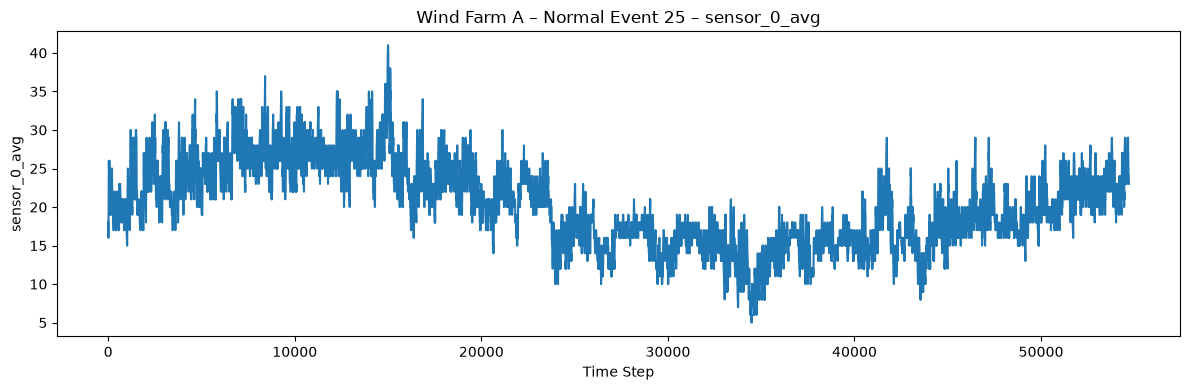

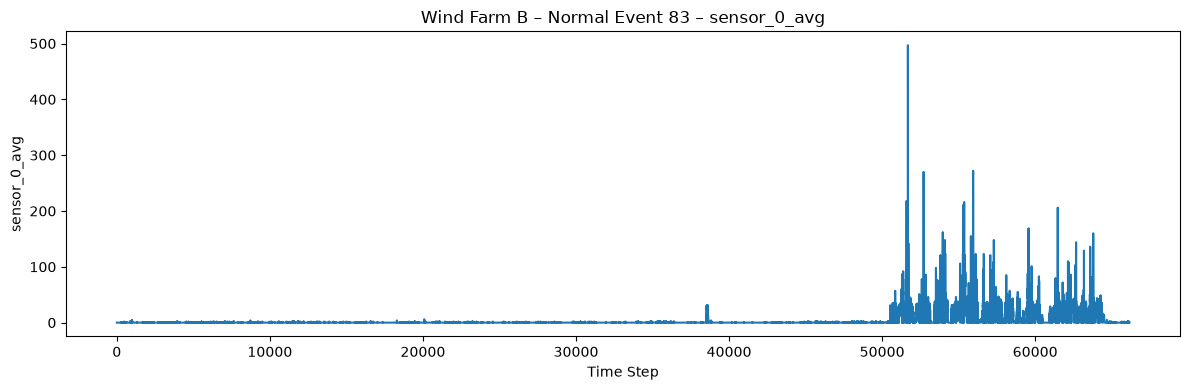

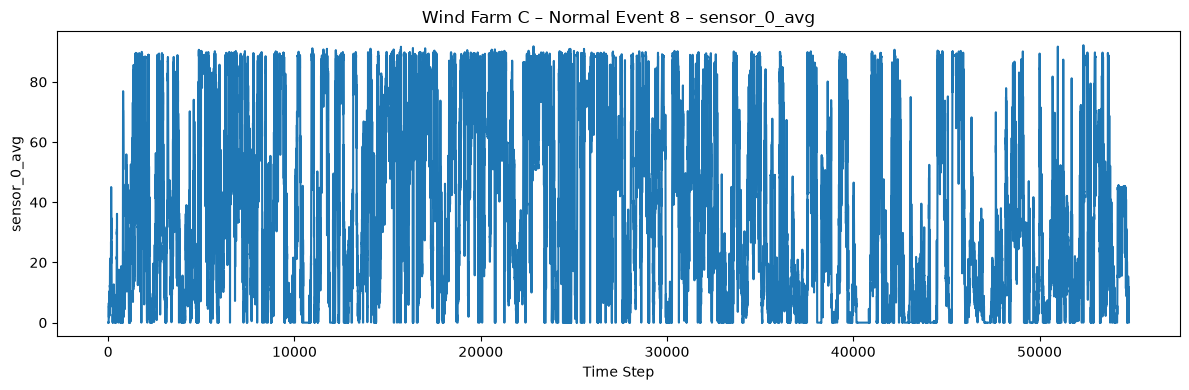

In [18]:
for farm_name in normal_samples:
    normal_df       = normal_samples[farm_name]["df"]
    normal_avg_cols = avg_cols_all[farm_name]["normal"]
    event_id        = normal_samples[farm_name]["event_id"]

    if not normal_avg_cols:
        print(f"Wind Farm {farm_name}: no Avg columns found.")
        continue

    sensor_col = normal_avg_cols[0]
    plt.figure(figsize=(12, 4))
    plt.plot(normal_df[sensor_col].values)
    plt.title(f"Wind Farm {farm_name} – Normal Event {event_id} – {sensor_col}")
    plt.xlabel("Time Step")
    plt.ylabel(sensor_col)
    plt.tight_layout()
    plt.show()


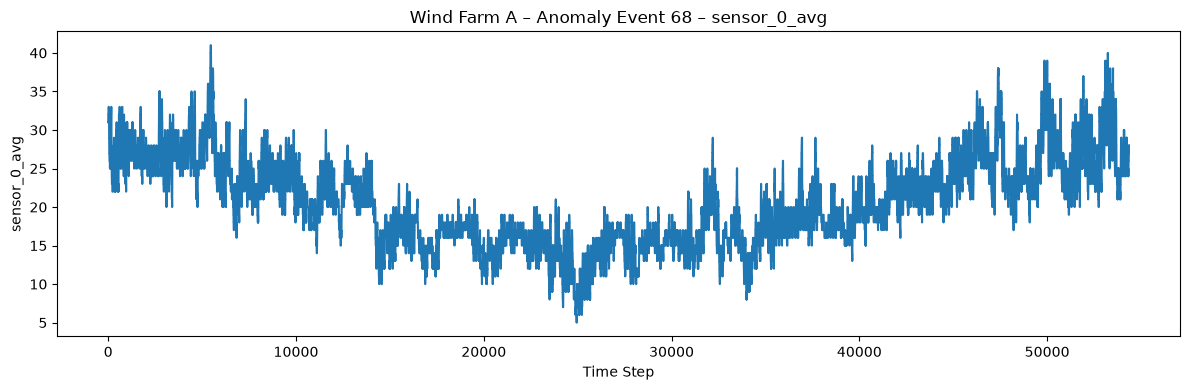

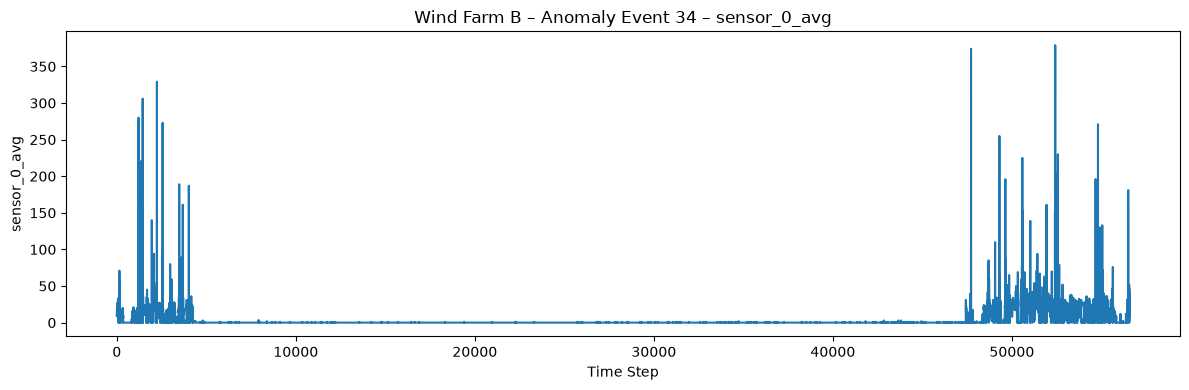

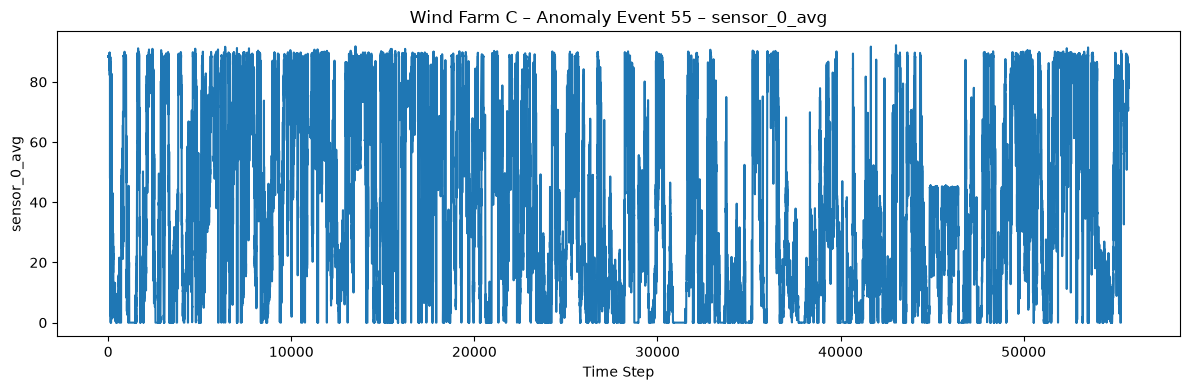

In [19]:
for farm_name in anomaly_samples:
    anomaly_df       = anomaly_samples[farm_name]["df"]
    anomaly_avg_cols = avg_cols_all[farm_name]["anomaly"]
    event_id         = anomaly_samples[farm_name]["event_id"]

    if not anomaly_avg_cols:
        print(f"Wind Farm {farm_name}: no Avg columns found.")
        continue

    sensor_col = anomaly_avg_cols[0]
    plt.figure(figsize=(12, 4))
    plt.plot(anomaly_df[sensor_col].values)
    plt.title(f"Wind Farm {farm_name} – Anomaly Event {event_id} – {sensor_col}")
    plt.xlabel("Time Step")
    plt.ylabel(sensor_col)
    plt.tight_layout()
    plt.show()


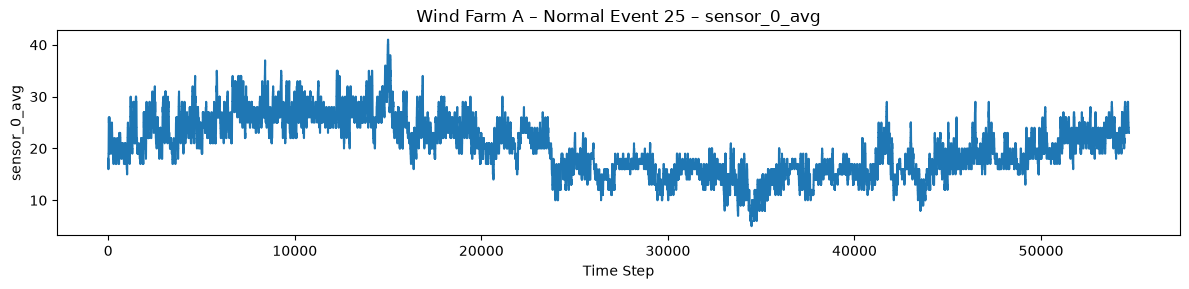

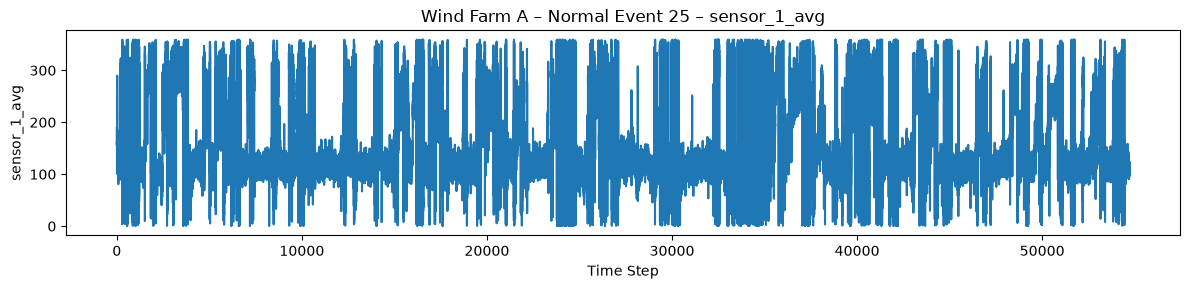

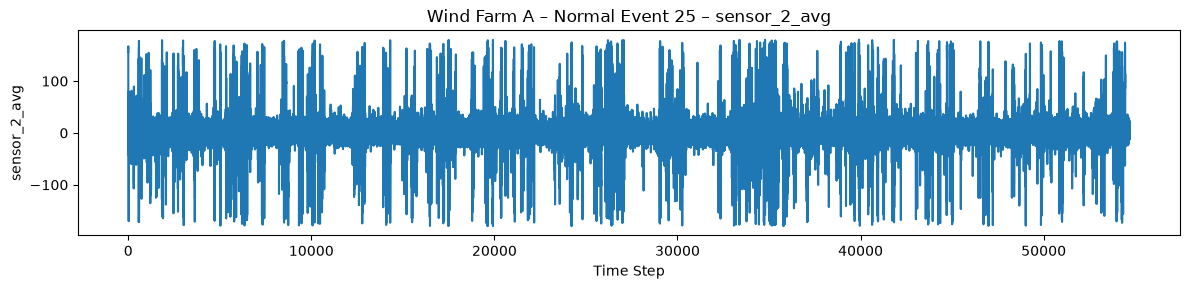

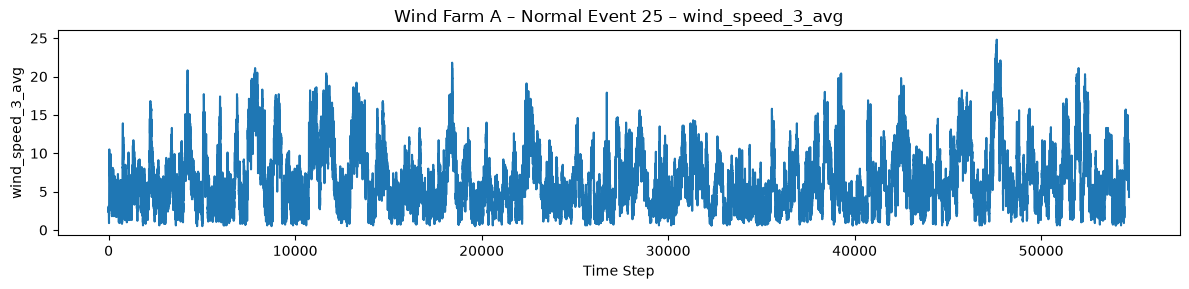

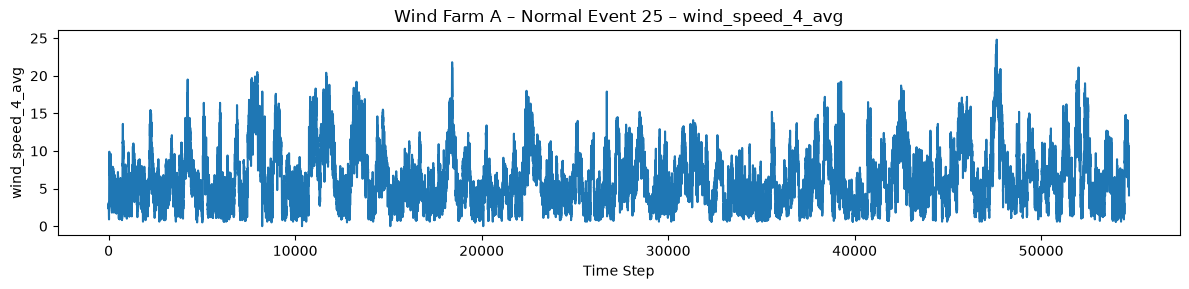

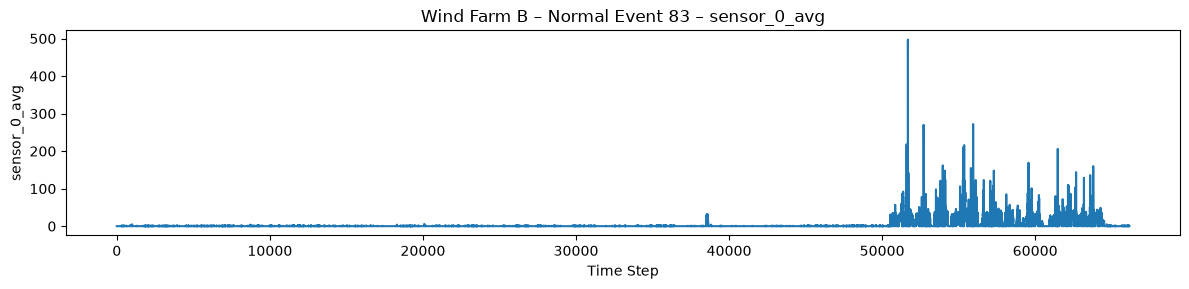

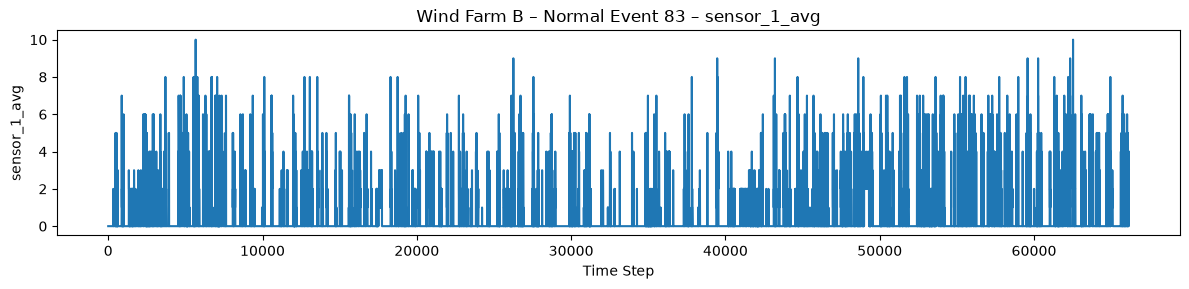

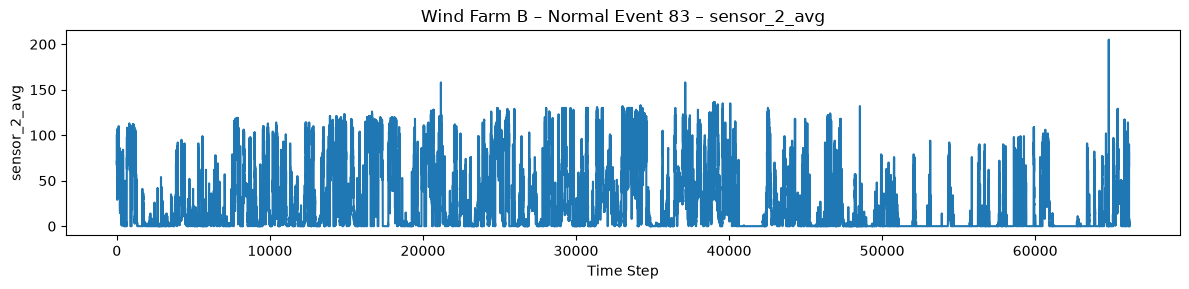

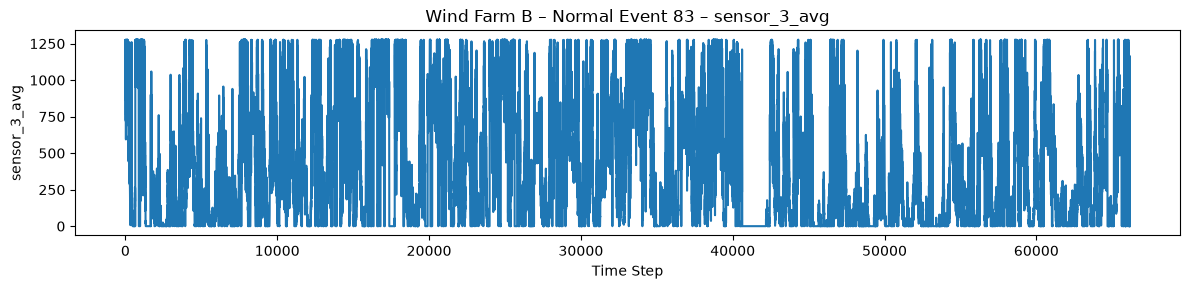

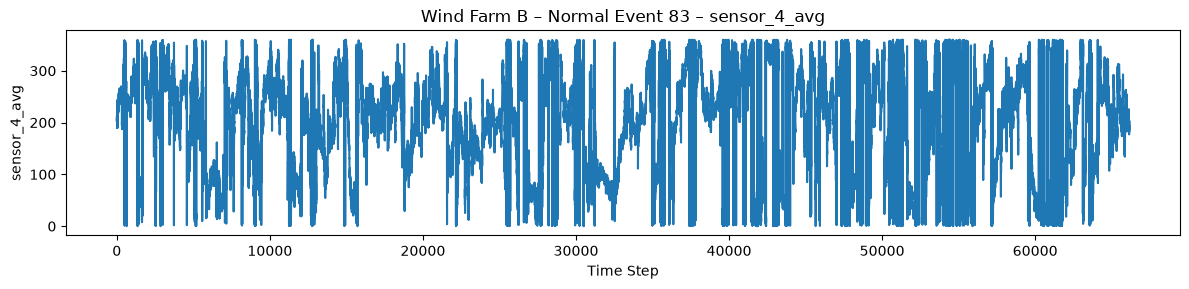

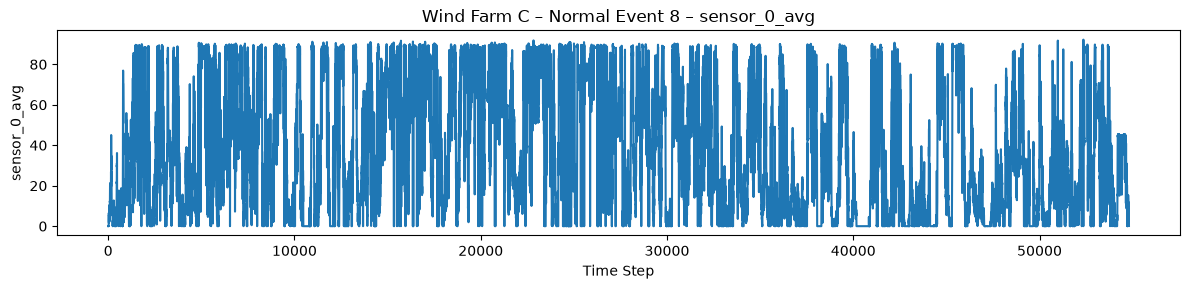

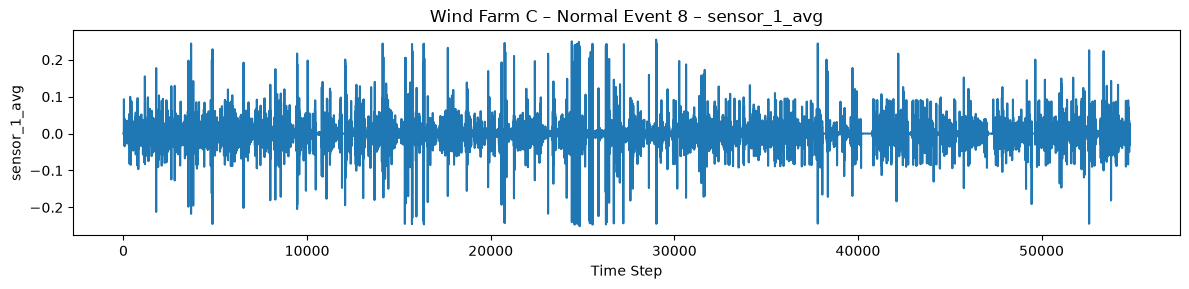

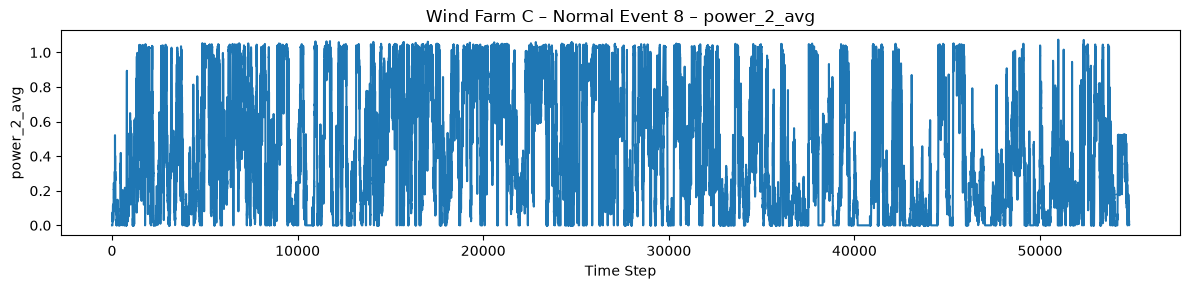

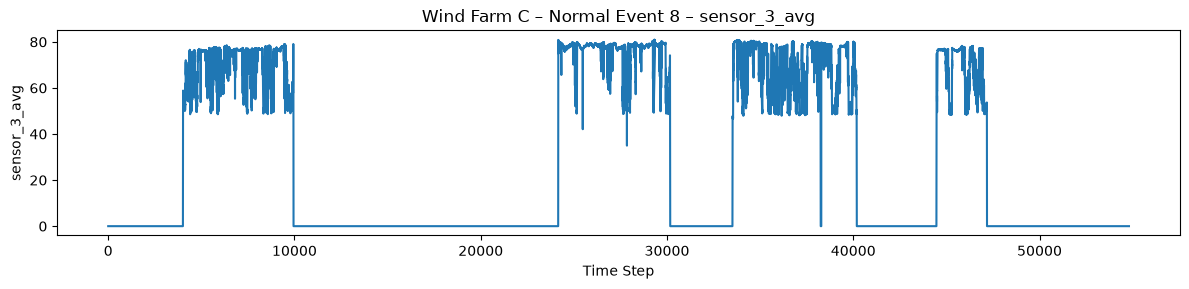

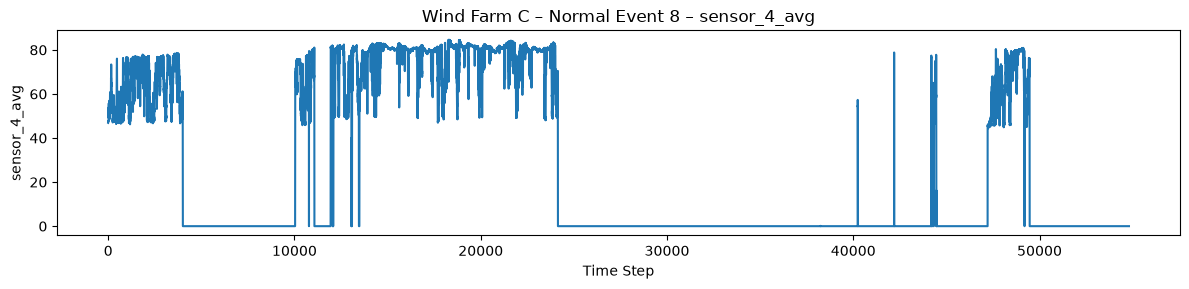

In [20]:
for farm_name in normal_samples:
    normal_df       = normal_samples[farm_name]["df"]
    normal_avg_cols = avg_cols_all[farm_name]["normal"]
    event_id        = normal_samples[farm_name]["event_id"]
    selected_cols   = normal_avg_cols[:5]

    for col in selected_cols:
        plt.figure(figsize=(12, 3))
        plt.plot(normal_df[col].values)
        plt.title(f"Wind Farm {farm_name} – Normal Event {event_id} – {col}")
        plt.xlabel("Time Step")
        plt.ylabel(col)
        plt.tight_layout()
        plt.show()


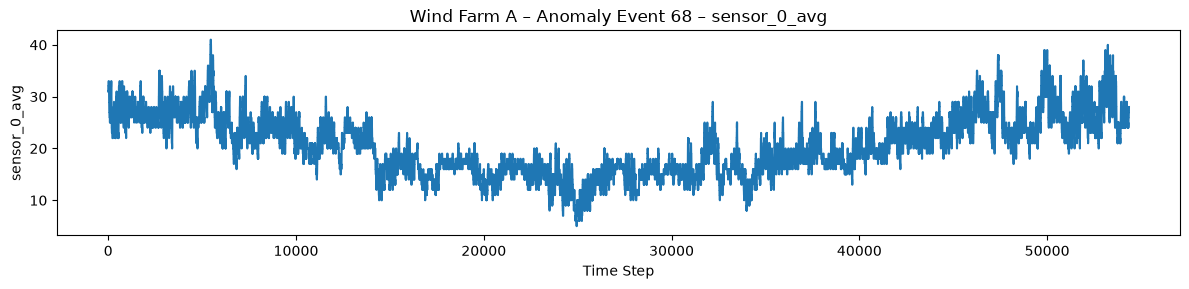

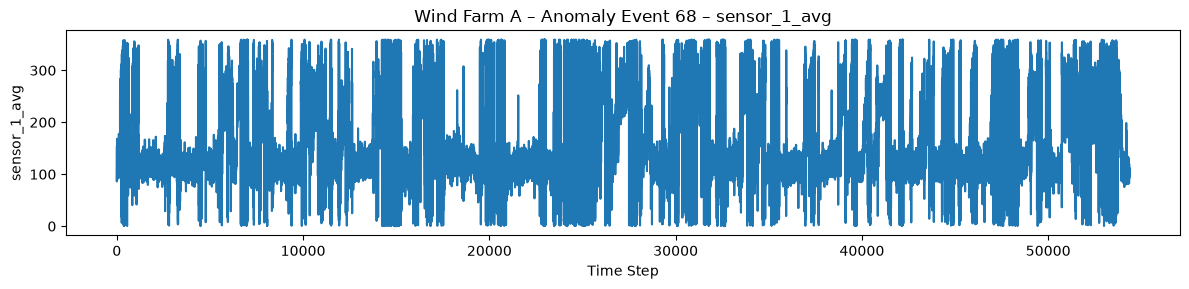

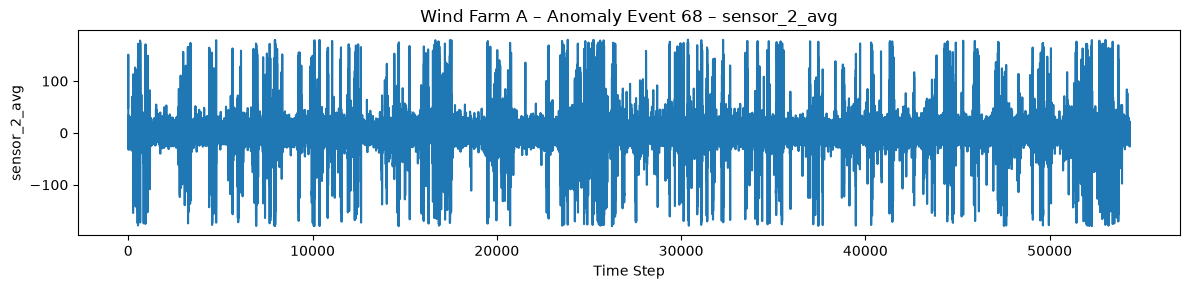

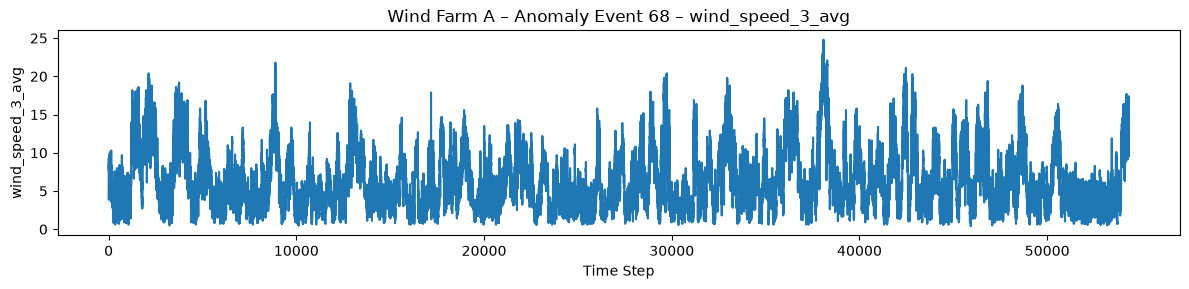

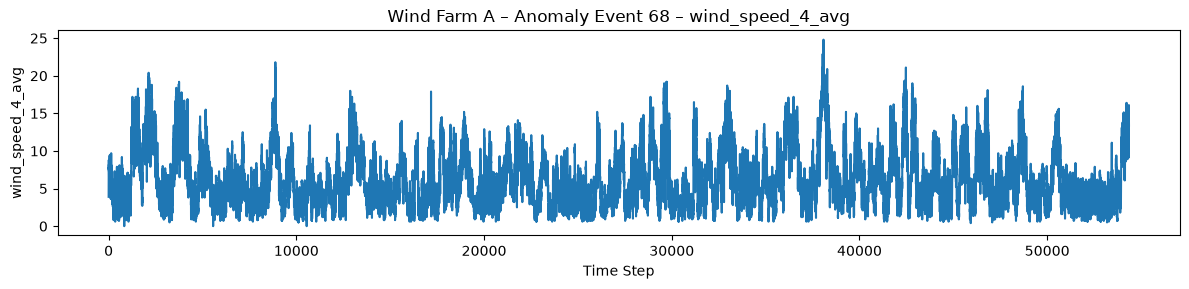

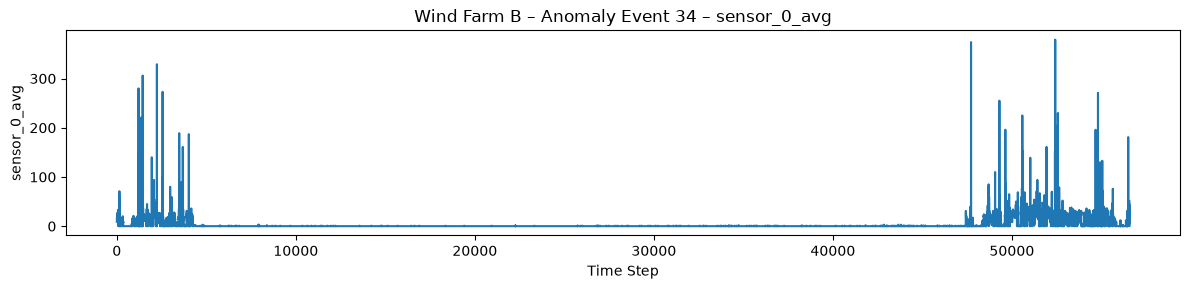

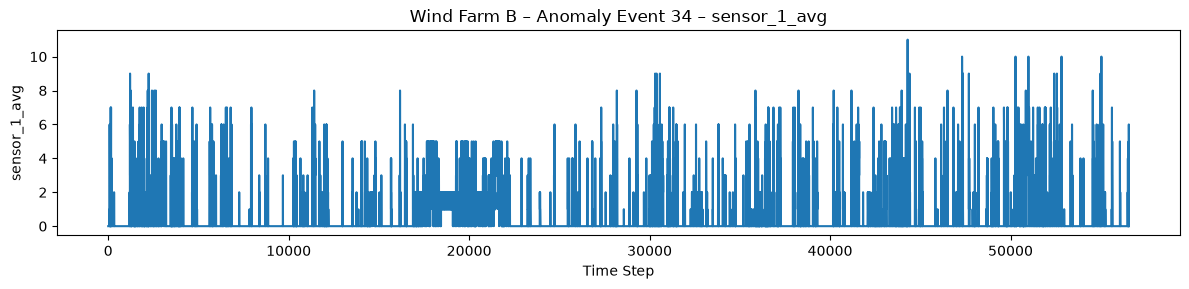

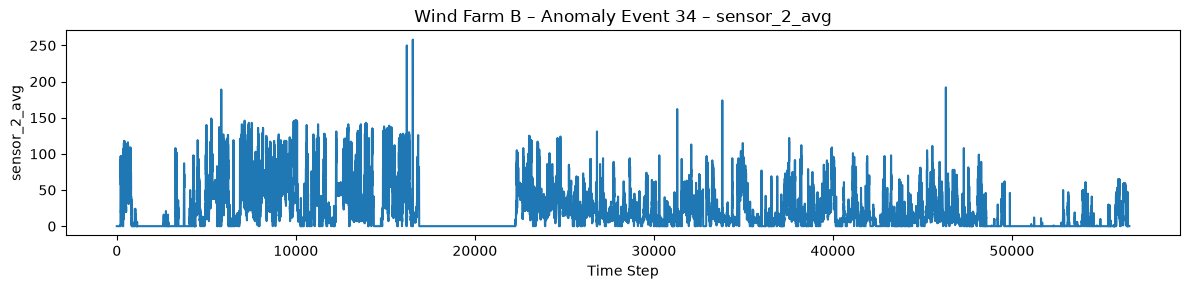

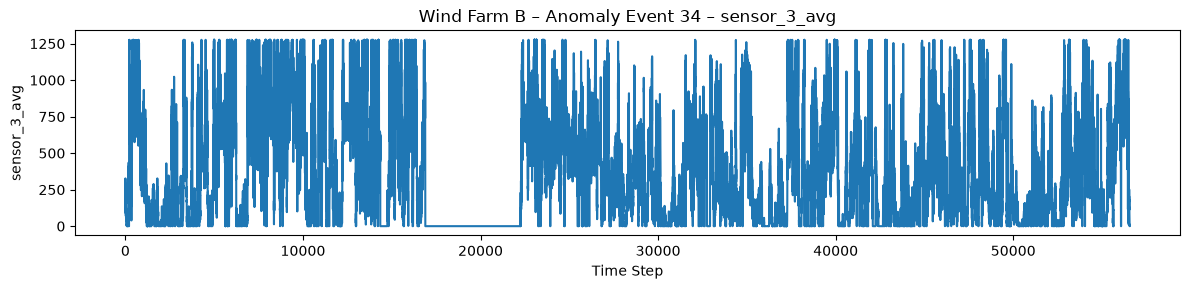

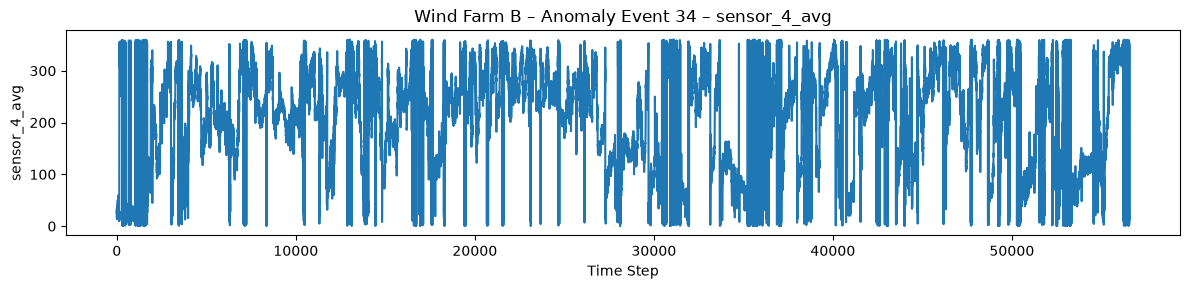

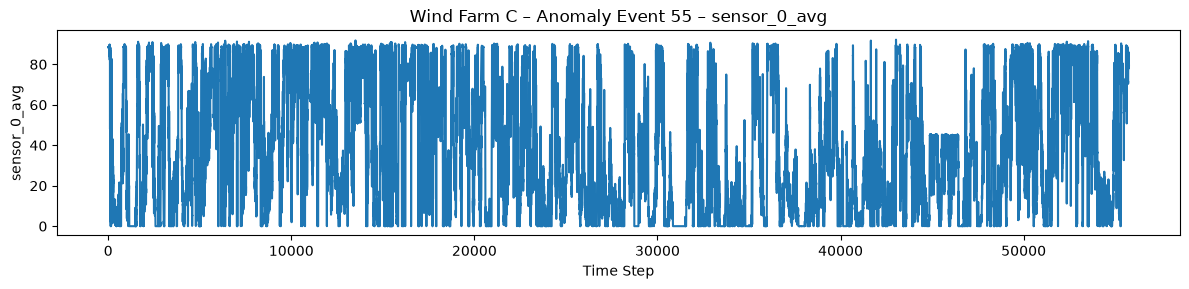

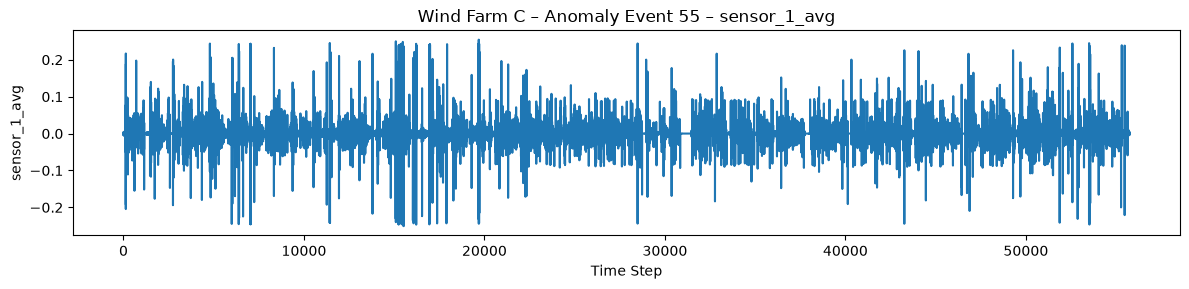

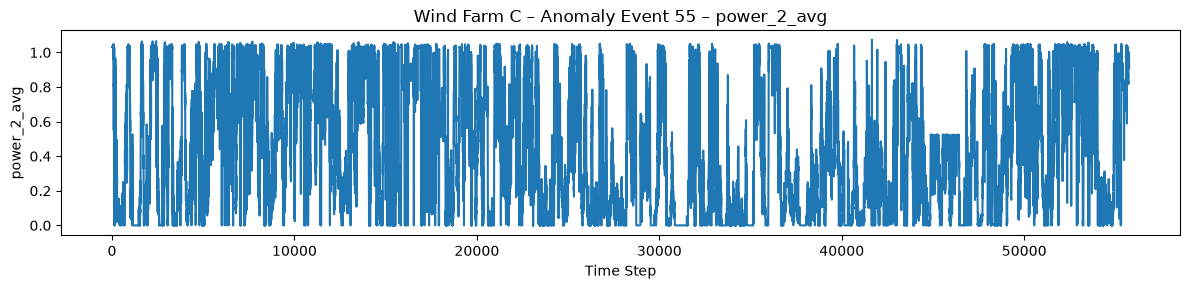

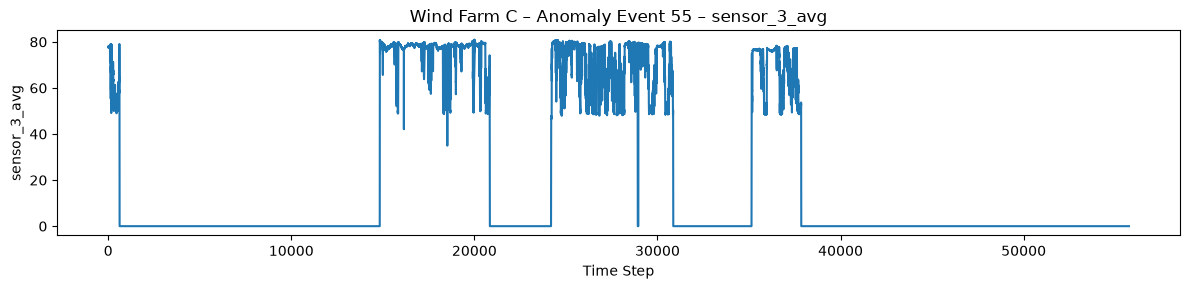

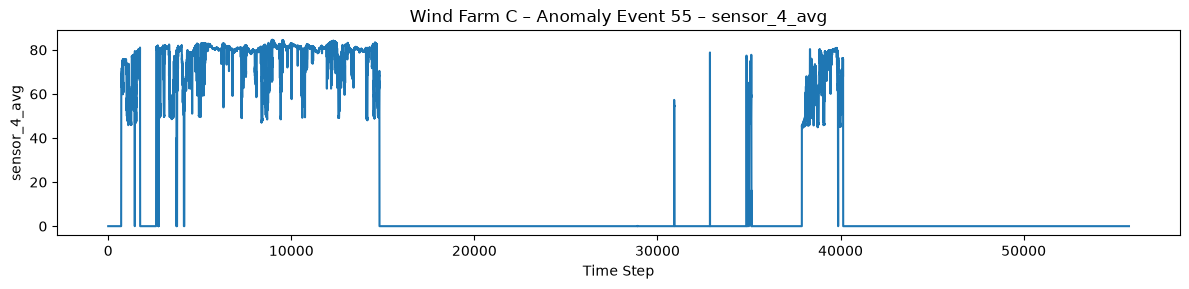

In [21]:
for farm_name in anomaly_samples:
    anomaly_df       = anomaly_samples[farm_name]["df"]
    normal_avg_cols  = avg_cols_all[farm_name]["normal"]
    event_id         = anomaly_samples[farm_name]["event_id"]
    selected_cols    = [col for col in normal_avg_cols[:5] if col in anomaly_df.columns]

    for col in selected_cols:
        plt.figure(figsize=(12, 3))
        plt.plot(anomaly_df[col].values)
        plt.title(f"Wind Farm {farm_name} – Anomaly Event {event_id} – {col}")
        plt.xlabel("Time Step")
        plt.ylabel(col)
        plt.tight_layout()
        plt.show()


In [22]:
import os

def fast_row_count(path, sep):
    # Count newlines minus header
    with open(path, "rb") as f:
        return sum(1 for _ in f) - 1

# Instead of read_csv_auto(file_path), do:
with open(file_path, "r") as f:
    header = f.readline()
    sep = ";" if header.count(";") > header.count(",") else ","
    n_cols = len(header.split(sep))
    n_avg_cols = sum(1 for col in header.split(sep) if "avg" in col.lower())

n_rows = fast_row_count(file_path, sep)

In [23]:
def fast_file_stats(path):
    """Return (n_rows, n_cols, n_avg_cols) without loading the full DataFrame."""
    with open(path, "rb") as f:
        raw = f.read()
    lines = raw.splitlines()
    if not lines:
        return 0, 0, 0
    header = lines[0].decode("utf-8", errors="replace")
    sep = ";" if header.count(";") > header.count(",") else ","
    cols = header.split(sep)
    n_cols = len(cols)
    n_avg_cols = sum(1 for c in cols if "avg" in c.lower())
    n_rows = len(lines) - 1  # exclude header
    return n_rows, n_cols, n_avg_cols


all_summary_rows = []

for farm_name, event_info in event_info_all.items():
    paths = FARMS[farm_name]

    for _, row in event_info.iterrows():
        event_id          = str(row["event_id"])
        event_label       = row["event_label"]
        event_description = row["event_description"]

        file_path = paths["dataset_dir"] / f"{event_id}.csv"

        if not file_path.exists():
            all_summary_rows.append({
                "farm": farm_name, "event_id": event_id,
                "event_label": event_label, "event_description": event_description,
                "file_exists": False, "n_rows": None, "n_cols": None, "n_avg_cols": None,
            })
            continue

        n_rows, n_cols, n_avg_cols = fast_file_stats(file_path)

        all_summary_rows.append({
            "farm": farm_name, "event_id": event_id,
            "event_label": event_label, "event_description": event_description,
            "file_exists": True, "n_rows": n_rows, "n_cols": n_cols, "n_avg_cols": n_avg_cols,
        })

file_summary = pd.DataFrame(all_summary_rows)
display(file_summary)

,farm,event_id,event_label,event_description,file_exists,n_rows,n_cols,n_avg_cols
0,A,68,anomaly,Transformer failure,True,54358,86,46
1,A,22,anomaly,Hydraulic group,True,53036,86,46
2,A,72,anomaly,Gearbox failure,True,54082,86,46
3,A,73,anomaly,Hydraulic group,True,54042,86,46
4,A,0,anomaly,Generator bearing failure,True,54986,86,46
...,...,...,...,...,...,...,...,...
90,C,37,normal,NaN,True,53713,957,238
91,C,29,normal,NaN,True,54865,957,238
92,C,1,normal,NaN,True,53569,957,238
93,C,20,normal,NaN,True,54001,957,238
